In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_squared_error
from sklearn.pipeline import Pipeline

print("ok")

ok


In [6]:
df = pd.read_csv("/kaggle/input/datasets/erkanturgut/polynomialregressiondata/3-customersatisfaction.csv")

In [7]:
df.head()

,Unnamed: 0,Customer Satisfaction,Incentive
0,0,-1.282447,1.010513
1,1,0.425298,2.281043
2,2,1.953070,4.415053
3,3,2.625838,10.563600
4,4,-1.426333,0.627365


In [10]:
df.drop("Unnamed: 0", axis = 1 , inplace=True)

In [11]:
df.head()

,Customer Satisfaction,Incentive
0,-1.282447,1.010513
1,0.425298,2.281043
2,1.953070,4.415053
3,2.625838,10.563600
4,-1.426333,0.627365


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer Satisfaction  100 non-null    float64
 1   Incentive              100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


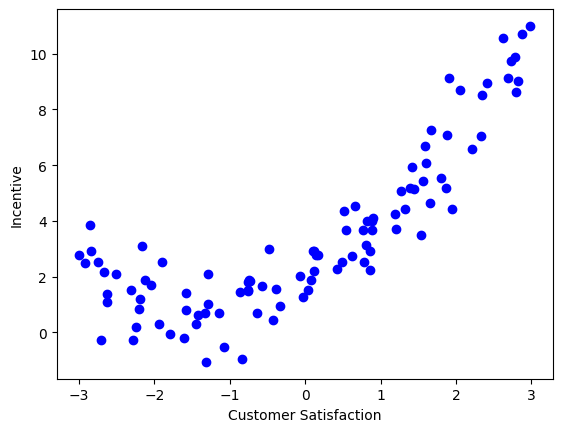

In [15]:
plt.scatter(df["Customer Satisfaction"], df["Incentive"],color ="b")
plt.xlabel("Customer Satisfaction")
plt.ylabel("Incentive")
plt.show()

In [17]:
# dependent -  independent features

X= df[["Customer Satisfaction"]]
y = df["Incentive"]

In [20]:
X.head()

,Customer Satisfaction
0,-1.282447
1,0.425298
2,1.953070
3,2.625838
4,-1.426333


In [21]:
y.head()

0     1.010513
1     2.281043
2     4.415053
3    10.563600
4     0.627365
Name: Incentive, dtype: float64

In [22]:
# train test split
X_train, X_test , y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 15)

In [23]:
X_train

,Customer Satisfaction
99,0.512504
3,2.625838
20,-0.865714
55,-1.145369
6,2.823460
...,...
28,1.191020
0,-1.282447
5,-1.311432
12,0.490521


In [25]:
#scaler

In [29]:
scaler = StandardScaler()

In [30]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test) 

In [31]:
regression = LinearRegression()

In [32]:
regression.fit(X_train,y_train)

LinearRegression()

In [33]:
## prediction


In [34]:
y_prediction = regression.predict(X_test)

In [35]:
y_prediction

array([ 4.65663741,  3.71913877,  1.64121789,  6.29646523,  3.46766736,
        5.7580845 ,  4.692485  ,  3.61616231,  5.62448003,  0.13472702,
        4.47909659,  4.8130839 ,  1.58319087,  0.30515983,  5.27634309,
        0.41711005, -0.7385295 , -0.32653914,  3.55906887,  1.19798631])

In [38]:
score = r2_score(y_test,y_prediction)
print(score)

0.2705652535622246


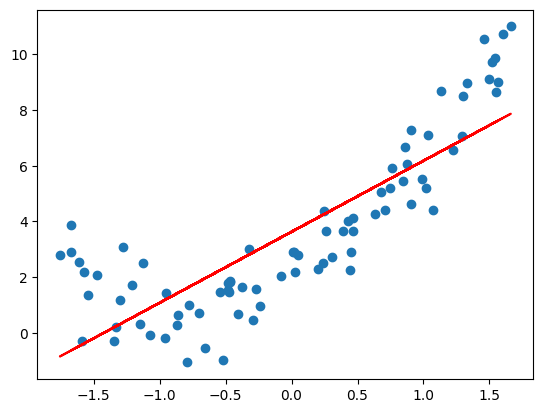

In [39]:
plt.scatter(X_train,y_train)
plt.plot(X_train, regression.predict(X_train), color = "r")
plt.show()